# 06. 고정 모델의 Test 최종 평가

내부 튜닝에서 선택한 모델과 임계값만 사용한다. Test 결과로 재학습하거나 임계값을 변경하지 않는다. 저장 모델의 SHA-256과 특징 계산 함수를 확인한 뒤 Test 전체를 한 번 평가한다. 결과는 PaySim 시간순 Test 구간의 성능으로 해석하고 실제 금융 데이터 성능으로 일반화하지 않는다.

In [1]:
import ast
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
model_run = "20261119T073653Z-1d0e70df"
model_dir = ROOT / "artifacts/models" / model_run
selection_path = model_dir / "frozen_selection.json"
selection = json.loads(selection_path.read_text())
name = selection["selected"]
spec = selection["candidates"][name]
threshold = spec["threshold"]
model_path = model_dir / f"{name}.txt"
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == spec["sha256"]
booster = lgb.Booster(model_file=str(model_path))
assert booster.feature_name() == spec["features"]
source = json.loads((ROOT / selection["source_manifest"]).read_text())
assert source["verified"]
assert not set(spec["features"]) & {
    "isFraud",
    "isFlaggedFraud",
    "newbalanceOrig",
    "newbalanceDest",
    "nameOrig",
    "nameDest",
}
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
report = ROOT / "artifacts/reports" / run_id
report.mkdir(parents=True)

# 학습 노트북에서 순수 특징 함수만 추출해 학습·튜닝 셀의 실행을 방지한다.
recipe_path = ROOT / "notebooks/05_bias_audit_temporal_validation.ipynb"
recipe = json.loads(recipe_path.read_text())
functions = []
for cell in recipe["cells"]:
    if cell["cell_type"] == "code":
        tree = ast.parse("".join(cell["source"]))
        functions.extend(
            node
            for node in tree.body
            if isinstance(node, ast.FunctionDef) and node.name == "enrich"
        )
assert len(functions) == 1
recipe_source = ast.unparse(functions[0])
namespace = {}
exec(compile(ast.Module(body=functions, type_ignores=[]), str(recipe_path), "exec"), namespace)
enrich = namespace["enrich"]
print("Fixed model:", model_run, name, "threshold:", threshold)

Fixed model: 20261119T073653Z-1d0e70df balance_features threshold: 0.006350361245177384


## Test 입력과 고정 예측

분할 manifest의 행 수·사기 건수·step 범위를 대조한다. 계좌 ID는 오류 분석 결과에만 유지하고 모델 입력에서 제외한다.

In [2]:
columns = source["model_features"] + ["isFraud", "nameOrig", "nameDest"]
test = pd.read_parquet(ROOT / source["parquet_path"] / "split=test", columns=columns)
expected = next(item for item in source["splits"] if item["split"] == "test")
assert len(test) == expected["rows"]
assert int(test.isFraud.sum()) == expected["fraud"]
assert test.step.min() == expected["min_step"] and test.step.max() == expected["max_step"]
valid_end = next(item["max_step"] for item in source["splits"] if item["split"] == "validation")
assert test.step.min() > valid_end
unknown_types = sorted(set(test["type"]) - set(selection["categories"]))
assert not unknown_types, unknown_types
labels = test.pop("isFraud")
test["type"] = pd.Categorical(test["type"], categories=selection["categories"])
enrich(test)
scores = booster.predict(test[spec["features"]])
assert len(scores) == len(labels) and np.isfinite(scores).all()
predicted = scores >= threshold
tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
p, r, _ = precision_recall_curve(labels, scores)
metrics = dict(
    precision=float(precision_score(labels, predicted, zero_division=0)),
    recall=float(recall_score(labels, predicted, zero_division=0)),
    f1=float(f1_score(labels, predicted, zero_division=0)),
    pr_auc=float(auc(r, p)),
    average_precision=float(average_precision_score(labels, scores)),
    tn=int(tn),
    fp=int(fp),
    fn=int(fn),
    tp=int(tp),
)
display(pd.DataFrame([dict(split="test", threshold=threshold, **metrics)]))
print("Rows:", len(labels), "Fraud:", int(labels.sum()))

,split,threshold,precision,recall,f1,pr_auc,average_precision,tn,fp,fn,tp
0,test,0.00635,1.0,0.999765,0.999883,0.999824,0.999766,1289265,0,1,4257


Rows: 1293523 Fraud: 4258


## 오류 분포와 산출물

거래 유형과 step별 오탐·미탐을 집계한다. 이 결과는 진단용으로 기록하며 모델 선택에 사용하지 않는다. Test를 관찰한 실행 이력을 별도 manifest로 보존한다.

,rows,fraud,false_positive,false_negative
type,,,,
CASH_IN,286869,0,0,0
CASH_OUT,440602,2129,0,0
DEBIT,9210,0,0,0
PAYMENT,444940,0,0,0
TRANSFER,111902,2129,0,1


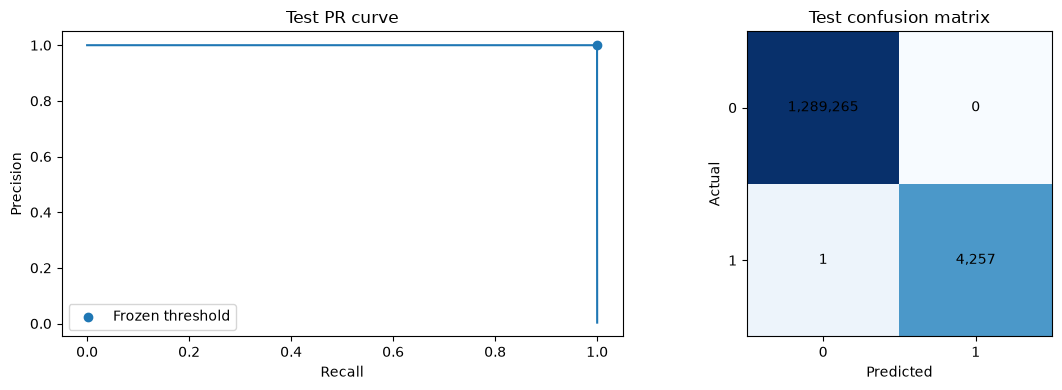

Test evaluation run: 20261119T075635Z-6a886eab


In [3]:
audit = test[["step", "type", "amount", "nameOrig", "nameDest"]].copy()
audit["label"] = labels.to_numpy()
audit["score"] = scores
audit["prediction"] = predicted
audit["false_positive"] = (labels.to_numpy() == 0) & predicted
audit["false_negative"] = (labels.to_numpy() == 1) & ~predicted
by_type = audit.groupby("type", observed=True).agg(
    rows=("label", "size"),
    fraud=("label", "sum"),
    false_positive=("false_positive", "sum"),
    false_negative=("false_negative", "sum"),
)
by_step = audit.groupby("step").agg(
    rows=("label", "size"),
    fraud=("label", "sum"),
    false_positive=("false_positive", "sum"),
    false_negative=("false_negative", "sum"),
)
display(by_type)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(r, p)
axes[0].scatter(metrics["recall"], metrics["precision"], label="Frozen threshold")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Test PR curve")
axes[0].legend()
matrix = np.array([[tn, fp], [fn, tp]])
axes[1].imshow(np.log1p(matrix), cmap="Blues")
for (i, j), value in np.ndenumerate(matrix):
    axes[1].text(j, i, f"{value:,}", ha="center", va="center", color="black")
axes[1].set(
    xticks=[0, 1], yticks=[0, 1], xlabel="Predicted", ylabel="Actual", title="Test confusion matrix"
)
fig.tight_layout()
fig.savefig(report / "test_evaluation.png", dpi=150)
plt.show()
audit.to_parquet(report / "test_predictions.parquet", index=False)
by_type.to_csv(report / "errors_by_type.csv")
by_step.to_csv(report / "errors_by_step.csv")
pd.DataFrame([metrics]).to_csv(report / "test_metrics.csv", index=False)
manifest = dict(
    run_id=run_id,
    completed_at_utc=datetime.now(timezone.utc).isoformat(),
    model_run_id=model_run,
    selected=name,
    model_sha256=spec["sha256"],
    selection_sha256=hashlib.sha256(selection_path.read_bytes()).hexdigest(),
    feature_recipe=recipe_source,
    feature_recipe_sha256=hashlib.sha256(recipe_source.encode()).hexdigest(),
    source_manifest=selection["source_manifest"],
    features=spec["features"],
    threshold=threshold,
    test_summary=expected,
    metrics=metrics,
    test_evaluated=True,
    test_used_for_selection=False,
    versions={"lightgbm": lgb.__version__, "sklearn": sklearn.__version__},
)
(report / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
print("Test evaluation run:", run_id)